In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import requests
from io import BytesIO

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(BytesIO(response.content)) as zip_ref:
    zip_ref.extractall("/content/")

print("Dataset downloaded successfully!")


Dataset downloaded successfully!


In [3]:

movies = pd.read_csv("/content/ml-latest-small/movies.csv")
ratings = pd.read_csv("/content/ml-latest-small/ratings.csv")

print("Movies Dataset:")
display(movies.head())

print("Ratings Dataset:")
display(ratings.head())

print("Movies shape:", movies.shape)
print("Ratings shape:", ratings.shape)


Movies Dataset:


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


Ratings Dataset:


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


Movies shape: (9742, 3)
Ratings shape: (100836, 4)


Total Movies: 9742
Total Users: 610
Total Ratings: 100836

Missing Values:
movieId    0
title      0
genres     0
dtype: int64
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


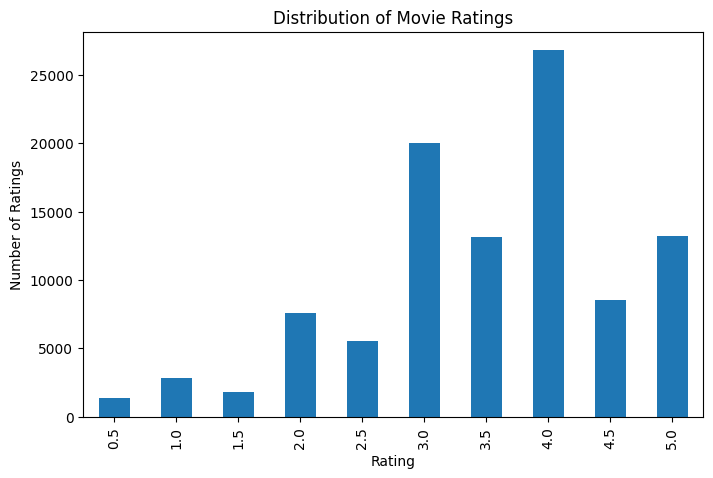

In [4]:

print("Total Movies:", movies["movieId"].nunique())
print("Total Users:", ratings["userId"].nunique())
print("Total Ratings:", len(ratings))

print("\nMissing Values:")
print(movies.isnull().sum())
print(ratings.isnull().sum())

plt.figure(figsize=(8, 5))
ratings["rating"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()


In [5]:

# Convert movie genres into numerical features

tfidf = TfidfVectorizer(token_pattern=r"[^|]+")

tfidf_matrix = tfidf.fit_transform(movies["genres"])

# Calculate similarity between movies

content_similarity = cosine_similarity(tfidf_matrix)

print("Content-Based Recommendation Model Created!")
print("Similarity Matrix Shape:", content_similarity.shape)

# Convert movie genres into numerical features

tfidf = TfidfVectorizer(token_pattern=r"[^|]+")

tfidf_matrix = tfidf.fit_transform(movies["genres"])

# Calculate similarity between movies

content_similarity = cosine_similarity(tfidf_matrix)

print("Content-Based Recommendation Model Created!")
print("Similarity Matrix Shape:", content_similarity.shape)


Content-Based Recommendation Model Created!
Similarity Matrix Shape: (9742, 9742)
Content-Based Recommendation Model Created!
Similarity Matrix Shape: (9742, 9742)


In [6]:

def recommend_by_genre(movie_name, number=10):

    movie_name = movie_name.lower()

    matches = movies[
        movies["title"].str.lower().str.contains(
            movie_name, regex=False, na=False
        )
    ]

    if matches.empty:
        print("Movie not found!")
        return

    movie_index = matches.index[0]

    similarity_scores = list(
        enumerate(content_similarity[movie_index])
    )

    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    recommended_indices = [
        i for i, score in similarity_scores[1:number+1]
    ]

    print("Movies similar to:", movies.iloc[movie_index]["title"])
    display(movies.iloc[recommended_indices][["title", "genres"]])



In [7]:

recommend_by_genre("Toy Story", 10)


Movies similar to: Toy Story (1995)


,title,genres
1706,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy
2355,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy
2809,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy
3000,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy
3568,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy
6194,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy
6486,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy
6948,"Tale of Despereaux, The (2008)",Adventure|Animation|Children|Comedy|Fantasy
7760,Asterix and the Vikings (Astérix et les Viking...,Adventure|Animation|Children|Comedy|Fantasy
8219,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy


In [8]:

user_movie_matrix = ratings.pivot_table(
    index="movieId",
    columns="userId",
    values="rating"
).fillna(0)

print("User-Movie Matrix:")
display(user_movie_matrix.head())

# Convert into a sparse matrix
movie_user_sparse = csr_matrix(user_movie_matrix.values)

print("Matrix prepared successfully!")


User-Movie Matrix:


userId,1,2,3,4,5,6,7,8,9,10,...,601,602,603,604,605,606,607,608,609,610
movieId,,,,,,,,,,,,,,,,,,,,,
1,4.0,0.0,0.0,0.0,4.0,0.0,4.5,0.0,0.0,0.0,...,4.0,0.0,4.0,3.0,4.0,2.5,4.0,2.5,3.0,5.0
2,0.0,0.0,0.0,0.0,0.0,4.0,0.0,4.0,0.0,0.0,...,0.0,4.0,0.0,5.0,3.5,0.0,0.0,2.0,0.0,0.0
3,4.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0


Matrix prepared successfully!


In [9]:

knn_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=21
)

knn_model.fit(movie_user_sparse)

print("Collaborative Filtering Model Trained Successfully!")


Collaborative Filtering Model Trained Successfully!


In [10]:

def recommend_for_user(user_id, number=10):

    if user_id not in ratings["userId"].values:
        print("User ID not found!")
        return

    user_ratings = ratings[ratings["userId"] == user_id]

    # Consider movies rated 3.5 or higher
    liked_movies = user_ratings[
        user_ratings["rating"] >= 3.5
    ]

    scores = {}

    for _, row in liked_movies.iterrows():

        movie_id = row["movieId"]

        if movie_id not in user_movie_matrix.index:
            continue

        movie_position = user_movie_matrix.index.get_loc(movie_id)

        distances, indices = knn_model.kneighbors(
            movie_user_sparse[movie_position],
            n_neighbors=21
        )

        for distance, neighbor_index in zip(distances[0], indices[0]):

            similarity = 1 - distance

            neighbor_id = user_movie_matrix.index[neighbor_index]

            if neighbor_id == movie_id:
                continue

            if neighbor_id in user_ratings["movieId"].values:
                continue

            if similarity <= 0:
                continue

            preference = row["rating"] - 3

            if neighbor_id not in scores:
                scores[neighbor_id] = [0, 0]

            scores[neighbor_id][0] += similarity * preference
            scores[neighbor_id][1] += similarity

    if not scores:
        print("Not enough ratings to generate recommendations.")
        return

    recommendations = []

    for movie_id, values in scores.items():

        final_score = values[0] / values[1]

        recommendations.append((movie_id, final_score))

    recommendations.sort(key=lambda x: x[1], reverse=True)

    result_ids = [movie_id for movie_id, score in recommendations[:number]]

    result = movies[movies["movieId"].isin(result_ids)].copy()

    result["score"] = result["movieId"].map(
        dict(recommendations)
    )

    result = result.sort_values("score", ascending=False)

    print("Personalized Recommendations for User:", user_id)

    display(result[["title", "genres", "score"]])


In [11]:

# Find users with the most ratings
print(ratings["userId"].value_counts().head())

# Test using User ID 1
recommend_for_user(1, 10)


userId
414    2698
599    2478
474    2108
448    1864
274    1346
Name: count, dtype: int64
Personalized Recommendations for User: 1


,title,genres,score
487,"War Room, The (1993)",Documentary,2.0
613,Trainspotting (1996),Comedy|Crime|Drama,2.0
922,"Godfather: Part II, The (1974)",Crime|Drama,2.0
935,Harold and Maude (1971),Comedy|Drama|Romance,2.0
1113,Waiting for Guffman (1996),Comedy,2.0
2104,Problem Child (1990),Children|Comedy,2.0
3141,Memento (2000),Mystery|Thriller,2.0
4615,Kill Bill: Vol. 1 (2003),Action|Crime|Thriller,2.0
5344,I Heart Huckabees (2004),Comedy,2.0
6030,North Country (2005),Drama,2.0


In [12]:

comparison = pd.DataFrame({
    "Technique": [
        "Content-Based Filtering",
        "Collaborative Filtering"
    ],
    "Working Method": [
        "Uses movie genres",
        "Uses user ratings"
    ],
    "Purpose": [
        "Finds similar movies",
        "Finds movies based on user preferences"
    ]
})

display(comparison)


,Technique,Working Method,Purpose
0,Content-Based Filtering,Uses movie genres,Finds similar movies
1,Collaborative Filtering,Uses user ratings,Finds movies based on user preferences
